# Власний проєкт: донавчання Qwen3-1.7B (LoRA) для маршрутизації відгуків громадян українською

**Лабораторна 5. Донавчання моделей (Fine-Tuning), пункт 1 - власне донавчання.** Задачу, дані, метрики й аналіз підібрано самостійно, а код побудовано на основі демо 01_bert_head і 03_sft_lora.

Ноутбук виконується зверху вниз у Google Colab на GPU T4 (*Runtime -> Change runtime type -> T4 GPU*). Числа у звіті (1.6) взято з виводів клітин цього ноутбука.

Структура відповідає завданню: 1.1 задача, 1.2 модель і дані, 1.3 модель до донавчання, 1.4 донавчання, 1.5 порівняння, 1.6 звіт.

In [ ]:
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate" scikit-learn
!pip uninstall -q -y torchao

In [ ]:
import json, os, re, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from IPython.display import Markdown, display
from peft import LoraConfig
from sklearn.metrics import classification_report, f1_score, precision_recall_fscore_support
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

set_seed(42)
assert torch.cuda.is_available(), "Потрібна GPU: оберіть Runtime -> T4 GPU"
print("GPU:", torch.cuda.get_device_name())
print("Памʼять GPU, GB:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

GPU: Tesla T4
Памʼять GPU, GB: 15.6


## 1.1. Задача

**Що вирішується.** Автоматична маршрутизація відгуків і звернень громадян про державні та муніципальні послуги (Дія, ЦНАП, сервісні центри тощо). Кожен відгук треба віднести до однієї з п'яти категорій:

| Категорія | Що означає | Що робить з нею система |
|---|---|---|
| `gratitude` | подяка, позитивний відгук | йде у статистику задоволеності |
| `complaint` | скарга, невдоволення | потрапляє в чергу швидкого реагування |
| `question` | питання, прохання про допомогу | передається оператору підтримки |
| `suggestion` | пропозиція, ідея | передається продуктовій команді |
| `neutral` | нейтральний коментар | зберігається в архіві |

**Хто користувач і як використовується результат.** Користувач - служба підтримки й аналітики сервісу, куди щодня надходять сотні й тисячі коротких текстів. Модель читає новий відгук і повертає категорію, за якою система сама розкладає потік за командами. Помилка не критична (оператор може перенаправити відгук), але два типи помилок коштують по-різному: скарга, віднесена до подяки, може лишитись непоміченою, а питання без відповіді псує досвід людини. Тому, крім загальної якості, ми окремо дивимось на recall класів `complaint` і `question`.

**Вхід.** Текст відгуку українською (від кількох слів до абзацу, до 700 символів), у тому вигляді, як його пише громадянин: з помилками, суржиком, емодзі.
**Вихід.** Один JSON-обʼєкт і більше нічого, наприклад `{"category": "complaint"}`: його розбирає код, тому формат має бути суворим.

**Чому потрібне донавчання, а не промпт.** Нижче ми це вимірюємо (розділи 1.3 і 1.5), а гіпотези такі:
1. **Межі категорій задає конвенція розмітників, а не здоровий глузд.** У даних відгук "Прекрасний сервіс, лише шкода, що скоротили час прийому по буднях" з 5 зірками розмічено як `complaint`, а репліку "Вступив на ІСТ цього року, тепер молюся, щоб переклали на ПУА" як `question`. Такі правила не вгадати з опису категорій, їх можна лише навчитися на прикладах.
2. **Сильний дисбаланс.** За описом датасету близько 64% відгуків - `gratitude`, а `question`, `neutral` і `suggestion` разом складають 12%. Саме рідкісні класи найважливіші для маршрутизації, а модель з промптом схильна їх змішувати.
3. **Довгий промпт дорогий.** Детальні правила й приклади треба передавати з кожним запитом. Донавчена модель тримає межі категорій у вагах і працює з коротким промптом (див. розрахунок вартості в 1.5).
4. **Мала локальна модель і приватність.** Відгуки містять прізвища працівників, номери справ і контакти. Мала модель на власному залізі не передає їх зовнішньому API, але з промптом може бути слабкою: це перевіряємо.
5. **Формат.** Система очікує чистий JSON з однією з п'яти міток.

**Чому не RAG.** RAG додає відповіді знання з документів, а тут нових знань не потрібно: категорія визначається самим текстом і конвенцією розмітки. Пошук схожих відгуків додав би індекс і затримку, але не гарантував би ні формат, ні узгодженість меж між класами.

**Критерії успіху.** (1) macro-F1 на тесті вищий, ніж у найкращого промпту; (2) 100% (або майже) відповідей розбираються як JSON з допустимою міткою; (3) короткий промпт замість довгого; (4) на загальних запитах поза задачею модель не починає відповідати JSON-ом.

## 1.2. Модель, дані і поділ на train / val / test

### Дані
**Джерело:** UAReviews (`KSE-RESEARCH-Group/UAReviews`, Kyiv School of Economics спільно з Мінцифри України). **Ліцензія:** CC BY 4.0 (за карткою датасету; код нижче читає її з Hugging Face). **Обсяг:** 11 580 українських відгуків. **Колонки:** `id`, `content` (текст), `rating` (1-5, інколи порожньо), `source` (джерело відгуку), `final_emotion`, `final_category`, `length`, `split` (`train`, `test`, `challenge`). Ми розвʼязуємо задачу за колонкою `final_category`.

**Відбір і підготовка:**
- дедуплікація за нормалізованим текстом; при збігу лишається копія з тестового набору, а копія з train видаляється, щоб тест не перетнувся з тренуванням;
- тексти довші за 700 символів обрізаються однаково на всіх етапах (щоб відповідь не обрізалась при тренуванні);
- тест беремо з офіційного `split == "test"` з природним розподілом класів, як у реальному потоці; `challenge` - додатковий набір для перевірки, оцінюється окремо.

### Поділ
- **validation** - збалансований, до 60 прикладів на клас із `train`: на ньому вибираємо промпт і контролюємо тренування; на збалансованому наборі macro-F1 має сенс навіть для рідкісних класів;
- **train** - решта `train`, але не більше 400 прикладів на клас (рідкісні класи беремо повністю). Без цього модель вчилась би переважно на `gratitude`;
- **test** - до 1000 прикладів із `split == "test"`, **challenge** - до 400 із `split == "challenge"`.

Перетин між наборами перевіряється (assert і окремий підрахунок). Тестові приклади в тренування не потрапляють, а промпт вибирається за val, а не за тестом.

In [ ]:
raw = load_dataset("KSE-RESEARCH-Group/UAReviews", split="train")
df = raw.to_pandas()
print(df.shape)
print(df.columns.tolist())
print("Розподіл за split:", df["split"].value_counts().to_dict())
print("Розподіл за source:", df["source"].value_counts().to_dict())
display(df["final_category"].value_counts().to_frame("кількість"))

license_text = "не вдалося прочитати"
try:
    from huggingface_hub import HfApi
    info = HfApi().dataset_info("KSE-RESEARCH-Group/UAReviews")
    license_text = str(info.card_data.license) if info.card_data else "не вказана"
except Exception as e:
    print("Не вдалося прочитати картку датасету:", e)
print("Ліцензія:", license_text)

CATS = {
    "Gratitude / Positive Feedback": "gratitude",
    "Complaint / Dissatisfaction": "complaint",
    "Question / Request for Help": "question",
    "Suggestion / Idea": "suggestion",
    "Neutral Comment": "neutral",
}
CLASSES = list(CATS.values())
for col in ("rating", "source"):
    if col not in df.columns:
        df[col] = np.nan
assert set(df["final_category"]) <= set(CATS), set(df["final_category"]) - set(CATS)

MAX_CHARS = 700
df["label"] = df["final_category"].map(CATS)
df["text"] = df["content"].str.strip().str.slice(0, MAX_CHARS)

priority = {"test": 0, "challenge": 1, "train": 2}
df = df.assign(_p=df["split"].map(priority), _key=df["content"].str.strip().str.lower())
n_before = len(df)
df = df.sort_values("_p", kind="stable").drop_duplicates("_key").drop(columns=["_p"]).reset_index(drop=True)
print(f"До дедуплікації: {n_before}, після: {len(df)}")

README.md:   0%|          | 0.00/3.20k [00:00<?, ?B/s]

benchmark_v1_splits.jsonl:   0%|          | 0.00/4.99M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11580 [00:00<?, ? examples/s]

(11580, 8)
['id', 'rating', 'content', 'source', 'final_emotion', 'final_category', 'length', 'split']
Розподіл за split: {'train': 8106, 'test': 1737, 'challenge': 1737}
Розподіл за source: {'original': 11510, 'cosmus': 70}


,кількість
final_category,
Gratitude / Positive Feedback,7440
Complaint / Dissatisfaction,2730
Question / Request for Help,615
Neutral Comment,418
Suggestion / Idea,377


Ліцензія: cc-by-4.0
До дедуплікації: 11580, після: 11564


In [ ]:
train_df = df[df["split"] == "train"]
test_df = df[df["split"] == "test"]
challenge_df = df[df["split"] == "challenge"]

test_df = test_df.sample(n=min(len(test_df), 1000), random_state=42)
challenge_df = challenge_df.sample(n=min(len(challenge_df), 400), random_state=42)

val_df = pd.concat([g.sample(min(len(g), 60), random_state=42) for _, g in train_df.groupby("label")])
pool = train_df.drop(val_df.index)

CAP = 400
fit_df = pd.concat([g.sample(min(len(g), CAP), random_state=42) for _, g in pool.groupby("label")])
fit_df = fit_df.sample(frac=1, random_state=42).reset_index(drop=True)

keys = lambda d: set(d["_key"])
assert not (keys(fit_df) & keys(val_df)) and not (keys(fit_df) & keys(test_df)) and not (keys(fit_df) & keys(challenge_df))
assert not (keys(val_df) & keys(test_df)) and not (keys(val_df) & keys(challenge_df)) and not (keys(test_df) & keys(challenge_df))

sets = [("train", fit_df), ("validation", val_df), ("test", test_df), ("challenge", challenge_df)]
sizes = pd.DataFrame({name: d["label"].value_counts().reindex(CLASSES).fillna(0).astype(int) for name, d in sets})
sizes.loc["усього"] = sizes.sum()
display(sizes)
print("перетин train і test:", len(keys(fit_df) & keys(test_df)), "| val і test:", len(keys(val_df) & keys(test_df)), "| train і val:", len(keys(fit_df) & keys(val_df)))

top = test_df["label"].value_counts().index[0]
print(f"Базовий рівень «завжди найчастіший клас» ({top}): accuracy = {(test_df['label'] == top).mean():.3f}")
print("Джерела в тесті:", test_df["source"].value_counts().to_dict())

print("\nПриклади з даних:")
for c in CLASSES:
    for t in fit_df[fit_df["label"] == c]["text"].head(2):
        print(f"[{c}] {t[:220]!r}")

,train,validation,test,challenge
label,,,,
gratitude,400,60,624,247
complaint,400,60,252,87
question,372,60,54,25
suggestion,195,60,31,24
neutral,228,60,39,17
усього,1595,300,1000,400


перетин train і test: 0 | val і test: 0 | train і val: 0
Базовий рівень «завжди найчастіший клас» (gratitude): accuracy = 0.624
Джерела в тесті: {'original': 991, 'cosmus': 9}

Приклади з даних:
[gratitude] 'Рідний інститут. Найкращі роки життя. Набуття важливих базових знань та диплома інженера-механіка.'
[gratitude] 'Зверталися за допомогою до РЕДЬКО ВАЛЕРІЇ ПАВЛІВНИ, уважно вислухавши, порадила ,як правильно діяти в нашій ситуації.Запевнила, що правда на нашому боці.  Залишилися задоволені , оскільки Валерія Павлівна завжди інформув'
[complaint] 'Міська влада не робить нічого, у чому немає особистої вигоди. Система міського транспорту принижена, зелені насадження у місті вирубуються, комунальне господарство у занепаді. Якщо найближчим часом у Харкові не зміниться'
[complaint] 'погано працюють, дві заявки вже дали... результату не буде ще 5 робочих днів!😠…'
[question] '@OscDomesticated @14druzivBanderi ЄВідновлення  здається 9тис платять?'
[question] 'Я про інше. В Конотопі святе міс

### Модель: Qwen3-1.7B
Обрано `Qwen/Qwen3-1.7B`. Це версія після post-training з чат-шаблоном (instruct-подібна), а не `Qwen3-1.7B-Base`. Задача - виконання інструкції у фіксованому форматі (JSON): така модель уже вміє слідувати системному промпту й тримати формат, тож "до донавчання" вона дає змістовну базову лінію. Base-модель без шаблону просто продовжує текст (див. демо 2) і потребувала б спершу вчити формат. Режим thinking вимкнено (`enable_thinking=False`): для класифікації міркування лише подовжують відповідь.

Розмір 1.7B вибрано за ресурсами. У fp16 ваги займають близько 3.4 GB (у демо 3 LoRA на цій моделі мала піковий обсяг памʼяті ≈ 3.8 GB із 15 GB T4), тож лишається запас на довші тексти й батч. Qwen3 багатомовна й працює з українською. Менша 0.6B має менший запас якості для української, а 4B у fp16 з LoRA вимагала б близько 9 GB і тренувалась би помітно довше. Ці альтернативи в цій роботі експериментально не порівнювались, вибір ґрунтується на розмірі й ресурсах.

## 1.3. Модель до донавчання

**Метрики.**
1. **Accuracy** - частка відгуків із правильною категорією.
2. **Macro-F1** - середнє F1 за п'ятьма категоріями, кожна має однакову вагу. Класи незбалансовані (близько 64% `gratitude`), тож лише accuracy приховала б слабкі класи: відповідь "завжди gratitude" дає високу accuracy й нульову F1 для чотирьох класів. Саме macro-F1 - головна метрика.
3. **F1, precision і recall за класами** - щоб бачити, де саме модель помиляється.
4. **Частка валідних відповідей** - чи розбирається відповідь як JSON з допустимою міткою. Невалідна відповідь вважається помилкою.

**Базовий рівень:** "завжди найчастіший клас".

**Промпти.** Порівнюємо три, від найпростішого до найдорожчого:
- *простий* - одне речення з переліком категорій;
- *детальний* - визначення категорій і 5 прикладів, які я написав сам;
- *few-shot* - ті самі визначення плюс по 2 приклади з train на кожну категорію (взяті з тренувального набору, не з val і не з test).

Найкращий промпт вибираємо за **validation**: так тест не впливає на вибір. На тесті оцінюємо простий і найкращий (за val) промпти, а найкращий стає базовою моделлю для порівняння в 1.5.

In [ ]:
MODEL_NAME = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

SHORT_PROMPT = (
    "Classify the Ukrainian review or citizen feedback into one category: "
    "gratitude, complaint, question, suggestion, neutral. "
    'Reply with JSON only, for example {"category": "complaint"}.'
)

RULES = """You classify Ukrainian reviews and citizen feedback about public services (Diia, service centers, administrative offices, schools, universities).
Choose exactly one category and reply with a single JSON object and nothing else, for example {"category": "complaint"}.

Categories:
- gratitude: thanks, praise, positive review.
- complaint: complaint, dissatisfaction, criticism of service, queues, staff or prices; also a mostly positive review that complains about a specific problem.
- question: a question or a request for help or information, including statements that ask for something.
- suggestion: a proposal or idea of how to improve something.
- neutral: a factual or neutral comment without clear praise, complaint, question or suggestion."""

DETAILED_PROMPT = RULES + """

Examples:
Review: Дуже дякую працівникам за швидке оформлення документів! -> {"category": "gratitude"}
Review: Третій раз приходжу, а черга стоїть на вулиці, сайт не працює. Ганьба. -> {"category": "complaint"}
Review: Підкажіть, будь ласка, як записатися на прийом онлайн? -> {"category": "question"}
Review: Було б добре додати окреме вікно для пенсіонерів. -> {"category": "suggestion"}
Review: Центр розташований на другому поверсі, працює з 9 до 18. -> {"category": "neutral"}"""

shots = []
for c in CLASSES:
    for t in fit_df[fit_df["label"] == c].sample(2, random_state=7)["text"]:
        shots.append("Review: " + t[:200].replace("\n", " ") + " -> " + json.dumps({"category": c}, ensure_ascii=False))
np.random.RandomState(1).shuffle(shots)
FEWSHOT_PROMPT = RULES + "\n\nExamples:\n" + "\n".join(shots)

PROMPTS = {"простий": SHORT_PROMPT, "детальний": DETAILED_PROMPT, "few-shot": FEWSHOT_PROMPT}
prompt_tokens = {name: len(tokenizer(p)["input_ids"]) for name, p in PROMPTS.items()}
print("Токенів у промптах:", prompt_tokens)

def build_prompts(texts, system_prompt):
    return [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": system_prompt}, {"role": "user", "content": t}],
            tokenize=False, add_generation_prompt=True, enable_thinking=False,
        )
        for t in texts
    ]

def generate_batch(model, prompts, max_new_tokens=32):
    tokenizer.padding_side = "left"
    inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
    tokenizer.padding_side = "right"
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id)
    new_tokens = out[:, inputs["input_ids"].shape[1]:]
    return [a.strip() for a in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

def classify_all(model, texts, system_prompt, batch_size=16):
    """Класифікує всі тексти; сортує за довжиною, щоб менше доповнювати, і повертає відповіді в початковому порядку."""
    model.eval()
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))
    answers = [None] * len(texts)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        outs = generate_batch(model, build_prompts([texts[i] for i in idx], system_prompt))
        for i, o in zip(idx, outs):
            answers[i] = o
    return answers

def is_clean_json(answer):
    try:
        json.loads(answer)
        return True
    except json.JSONDecodeError:
        return False

def parse_label(answer):
    """Знімає обгортку ```json ... ```, повертає одну з міток або None, якщо відповідь не за форматом."""
    text = answer.strip()
    if text.startswith("```"):
        text = text.strip("`").removeprefix("json").strip()
    try:
        obj = json.loads(text)
    except json.JSONDecodeError:
        return None
    if isinstance(obj, dict) and obj.get("category") in CLASSES:
        return obj["category"]
    return None

def score(answers, gold):
    preds = [parse_label(a) for a in answers]
    pred_for_f1 = [p if p is not None else "invalid" for p in preds]
    f1s = f1_score(gold, pred_for_f1, labels=CLASSES, average=None, zero_division=0)
    n = len(gold)
    metrics = {
        "Чистий JSON, %": 100 * sum(is_clean_json(a) for a in answers) / n,
        "Валідна відповідь, %": 100 * sum(p is not None for p in preds) / n,
        "Accuracy, %": 100 * sum(p == g for p, g in zip(preds, gold)) / n,
        "Macro-F1, %": 100 * f1s.mean(),
    }
    for c, f in zip(CLASSES, f1s):
        metrics[f"F1 {c}, %"] = 100 * f
    return metrics, preds

def run_eval(model, texts, gold, system_prompt):
    """Оцінка моделі на наборі: відповіді, мітки, метрики й час."""
    t0 = time.time()
    outs = classify_all(model, texts, system_prompt)
    dt = time.time() - t0
    metrics, preds = score(outs, gold)
    return dict(outs=outs, preds=preds, metrics=metrics, time=dt)

test_texts, test_gold = test_df["text"].tolist(), test_df["label"].tolist()
val_texts, val_gold = val_df["text"].tolist(), val_df["label"].tolist()
chal_texts, chal_gold = challenge_df["text"].tolist(), challenge_df["label"].tolist()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Токенів у промптах: {'простий': 37, 'детальний': 330, 'few-shot': 690}


In [ ]:
t0 = time.time()
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
print(f"Модель завантажено за {time.time() - t0:.0f} с; памʼять GPU після завантаження: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

val_res = {}
for name, p in PROMPTS.items():
    val_res[name] = run_eval(base_model, val_texts, val_gold, p)
    m = val_res[name]["metrics"]
    print(f"val, {name} ({prompt_tokens[name]} токенів): accuracy {m['Accuracy, %']:.1f}, macro-F1 {m['Macro-F1, %']:.1f}, "
          f"валідних {m['Валідна відповідь, %']:.1f}%, {val_res[name]['time']:.0f} с")

display(pd.DataFrame({n: r["metrics"] for n, r in val_res.items()}).round(1))
best_name = max(val_res, key=lambda k: (val_res[k]["metrics"]["Macro-F1, %"], val_res[k]["metrics"]["Accuracy, %"]))
print("Найкращий промпт за macro-F1 на валідації:", best_name)

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель завантажено за 68 с; памʼять GPU після завантаження: 3.44 GB
val, простий (37 токенів): accuracy 72.3, macro-F1 71.9, валідних 100.0%, 25 с
val, детальний (330 токенів): accuracy 73.3, macro-F1 72.6, валідних 100.0%, 43 с
val, few-shot (690 токенів): accuracy 73.0, macro-F1 71.7, валідних 100.0%, 66 с


,простий,детальний,few-shot
"Чистий JSON, %",100.0,100.0,100.0
"Валідна відповідь, %",100.0,100.0,100.0
"Accuracy, %",72.3,73.3,73.0
"Macro-F1, %",71.9,72.6,71.7
"F1 gratitude, %",86.4,78.4,80.8
"F1 complaint, %",69.6,78.7,75.9
"F1 question, %",74.7,82.7,76.9
"F1 suggestion, %",64.3,55.7,69.6
"F1 neutral, %",64.6,67.2,55.6


Найкращий промпт за macro-F1 на валідації: детальний


In [ ]:
majority = max(set(test_gold), key=test_gold.count)
maj_metrics, _ = score([json.dumps({"category": majority})] * len(test_gold), test_gold)
print(f"Базовий рівень: завжди '{majority}': accuracy {maj_metrics['Accuracy, %']:.1f}%, macro-F1 {maj_metrics['Macro-F1, %']:.1f}%")

base = {}
for name in dict.fromkeys(["простий", best_name]):
    base[name] = run_eval(base_model, test_texts, test_gold, PROMPTS[name])
    m = base[name]["metrics"]
    print(f"test, {name}: accuracy {m['Accuracy, %']:.1f}, macro-F1 {m['Macro-F1, %']:.1f}, валідних {m['Валідна відповідь, %']:.1f}%, {base[name]['time']:.0f} с")

chal_before = run_eval(base_model, chal_texts, chal_gold, PROMPTS[best_name])
print(f"challenge, {best_name}: macro-F1 {chal_before['metrics']['Macro-F1, %']:.1f}")

print(f"\n10 прикладів відповідей моделі до донавчання (промпт: {best_name}):")
for t, a, g in list(zip(test_texts, base[best_name]["outs"], test_gold))[:10]:
    print(f"істина: {g} | відповідь: {a[:70]!r}\n    {t[:120]!r}")

Базовий рівень: завжди 'gratitude': accuracy 62.4%, macro-F1 15.4%
test, простий: accuracy 85.5, macro-F1 69.1, валідних 100.0%, 53 с
test, детальний: accuracy 88.3, macro-F1 71.0, валідних 100.0%, 121 с
challenge, детальний: macro-F1 65.8

10 прикладів відповідей моделі до донавчання (промпт: детальний):
істина: gratitude | відповідь: '{"category": "gratitude"}'
    'Вчимося в академії перший рік, дитині поки що подобається. Заняття цікаві.'
істина: complaint | відповідь: '{"category": "complaint"}'
    'Повний провал та саботаж! Перед виборами треба було змінити місце голосування. Працюють вкрай повільно, збирають кіломет'
істина: gratitude | відповідь: '{"category": "gratitude"}'
    "Чудовий салон! Чудова атмосфера! Чудові майстри ! Обов'язково повернусь за тату і пірсингом. Однозначно 5 зірок."
істина: gratitude | відповідь: '{"category": "gratitude"}'
    'Класний коледж, отримую стипендію.\nНавчаюся на 3 курсі.'
істина: gratitude | відповідь: '{"category": "gratitude"}'
    'Був

## 1.4. Донавчання (LoRA)

**Метод.** SFT з LoRA: ваги базової моделі (fp16) заморожені, навчаються лише малі адаптери в усіх лінійних шарах. Повне донавчання 1.7 млрд параметрів на T4 нереалістичне: лише стани оптимізатора займали б десятки гігабайтів. LoRA навчає близько 1-2% параметрів і вкладається в кілька гігабайтів. Адаптери QLoRA (4-бітні ваги) тут не потрібні: модель невелика й у fp16 вміщується, а LoRA швидша й без втрат на квантизацію (порівняння LoRA і QLoRA - у демо 3).

**Формат тренування.** Кожен приклад - діалог із трьох повідомлень (system - короткий промпт, user - відгук, assistant - JSON із категорією). Loss рахується лише на відповіді асистента (`assistant_only_loss=True`): інакше модель вчилась би передбачати й системний промпт (він однаковий у всіх прикладах), і тексти відгуків, які їй генерувати не потрібно. `enable_thinking=False` у `chat_template_kwargs` робить формат тренування таким самим, як в інференсі. У тренуванні використовується **короткий** промпт: межі категорій модель має засвоїти у вагах.

**Гіперпараметри і чому такі.** Значення взято зі стандартних рекомендацій для LoRA та з демо 3, де вони працювали на цій самій моделі; окремий підбір не проводився (час на T4 обмежений).

| Параметр | Значення | Обґрунтування |
|---|---|---|
| LoRA r | 16 | Для класифікації на 5 категорій у вузькому форматі такого рангу достатньо; більший r додав би параметрів без очевидної користі (не перевірялось) |
| lora_alpha | 32 | Масштаб alpha / r = 2, типове співвідношення, що задає силу впливу адаптера |
| lora_dropout | 0.05 | Легка регуляризація, бо тренувальний набір малий (менше двох тисяч прикладів) |
| target_modules | all-linear | Адаптери в усіх лінійних шарах, а не лише в увазі: зазвичай це дає кращу якість за ту саму кількість кроків |
| learning rate | 2e-4, cosine, warmup 10 кроків | Типове значення для LoRA (більше, ніж для повного донавчання, бо вчаться лише малі адаптери); cosine плавно знижує lr, warmup прибирає стрибки на початку |
| Батч | 4 * 2 = 8 | Мікробатч 4 економить памʼять, накопичення градієнта 2 дає ефективний батч 8 |
| Кроки | 250 (приблизно одна епоха) | Точна кількість епох друкується нижче. Validation loss кожні 25 кроків покаже, чи не почалось перенавчання |
| max_length | 512 | Приклади довші за це відкидаємо (а не обрізаємо): обрізання з кінця прибрало б відповідь із loss |
| Обмеження на клас | 400 прикладів | Вирівнює розподіл класів у тренуванні; тест лишається з природним розподілом |
| Точність | fp16 + gradient checkpointing | T4 не підтримує bf16; чекпоінтинг економить памʼять ціною швидкості |

**Перенавчання.** Контролюємо за validation loss: код нижче порівнює його мінімум з останнім значенням і друкує висновок. Якщо loss помітно зросте після мінімуму, наступним кроком було б зменшити кількість кроків або збільшити dropout.

In [ ]:
def to_messages(text, label):
    return {
        "messages": [
            {"role": "system", "content": SHORT_PROMPT},
            {"role": "user", "content": text},
            {"role": "assistant", "content": json.dumps({"category": label})},
        ],
        "chat_template_kwargs": {"enable_thinking": False},
    }

MAX_LEN = 512

def build_ds(frame, name):
    rows = [to_messages(t, l) for t, l in zip(frame["text"], frame["label"])]
    lens = [len(tokenizer(tokenizer.apply_chat_template(r["messages"], tokenize=False, enable_thinking=False))["input_ids"]) for r in rows]
    kept = [r for r, n in zip(rows, lens) if n <= MAX_LEN]
    print(f"{name}: прикладів {len(rows)}, довжина в токенах: середня {np.mean(lens):.0f}, 95-й перцентиль {int(np.percentile(lens, 95))}, "
          f"макс {max(lens)}; відкинуто за max_length={MAX_LEN}: {len(rows) - len(kept)}")
    return Dataset.from_list(kept)

train_ds = build_ds(fit_df, "train")
val_ds = build_ds(val_df, "validation")
print("Приклад:", train_ds[0]["messages"])

peft_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")

sft_config = SFTConfig(
    output_dir="uareviews-lora",
    max_length=MAX_LEN,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=8,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    max_steps=250,
    eval_strategy="steps",
    eval_steps=25,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    logging_steps=25,
    save_strategy="no",
    report_to="none",
    seed=42,
)

trainer = SFTTrainer(
    model=base_model,
    args=sft_config,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    peft_config=peft_config,
)
trainer.model.print_trainable_parameters()
n_trainable = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in trainer.model.parameters())

eff_batch = sft_config.per_device_train_batch_size * sft_config.gradient_accumulation_steps
epochs = sft_config.max_steps * eff_batch / len(train_ds)
lc = trainer.model.peft_config["default"]
print(f"LoRA: r={lc.r}, alpha={lc.lora_alpha}, dropout={lc.lora_dropout}, масштаб alpha/r={lc.lora_alpha / lc.r}")
print(f"Ефективний батч: {sft_config.per_device_train_batch_size} * {sft_config.gradient_accumulation_steps} = {eff_batch}; "
      f"кроків {sft_config.max_steps}; це {epochs:.2f} епохи по {len(train_ds)} прикладах")

train: прикладів 1595, довжина в токенах: середня 139, 95-й перцентиль 206, макс 474; відкинуто за max_length=512: 0
validation: прикладів 300, довжина в токенах: середня 136, 95-й перцентиль 199, макс 376; відкинуто за max_length=512: 0
Приклад: [{'content': 'Classify the Ukrainian review or citizen feedback into one category: gratitude, complaint, question, suggestion, neutral. Reply with JSON only, for example {"category": "complaint"}.', 'role': 'system'}, {'content': 'Перший у Харкові навчальний заклад із статусом Університет. Має два корпуси, розташовані з різних боків площі Свободи.', 'role': 'user'}, {'content': '{"category": "neutral"}', 'role': 'assistant'}]


Tokenizing train dataset:   0%|          | 0/1595 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1595 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1595 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1595 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030
LoRA: r=16, alpha=32, dropout=0.05, масштаб alpha/r=2.0
Ефективний батч: 4 * 2 = 8; кроків 250; це 1.25 епохи по 1595 прикладах


In [ ]:
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
train_minutes = (time.time() - t0) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9
print(f"Тривалість тренування: {train_minutes:.2f} хв; пікова памʼять GPU: {peak_gb:.2f} GB")

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,0.303067,0.153960,0.051605,0.959293,26768.000000
50,0.088195,0.076819,0.097516,0.973547,54817.000000
75,0.068388,0.077843,0.053816,0.970029,81660.000000
100,0.065167,0.052575,0.058756,0.982136,110022.000000
125,0.059168,0.063900,0.062328,0.974689,138089.000000
150,0.058725,0.048634,0.059589,0.980217,166694.000000
175,0.054051,0.058261,0.063697,0.979258,193435.000000
200,0.041046,0.048218,0.057311,0.981223,220947.000000
225,0.017800,0.046120,0.050988,0.982045,249159.000000
250,0.016411,0.045574,0.049888,0.982091,276885.000000


Тривалість тренування: 9.31 хв; пікова памʼять GPU: 4.38 GB


,крок,train loss,validation loss
0,25,0.3031,0.1540
1,50,0.0882,0.0768
2,75,0.0684,0.0778
3,100,0.0652,0.0526
4,125,0.0592,0.0639
5,150,0.0587,0.0486
6,175,0.0541,0.0583
7,200,0.0410,0.0482
8,225,0.0178,0.0461
9,250,0.0164,0.0456


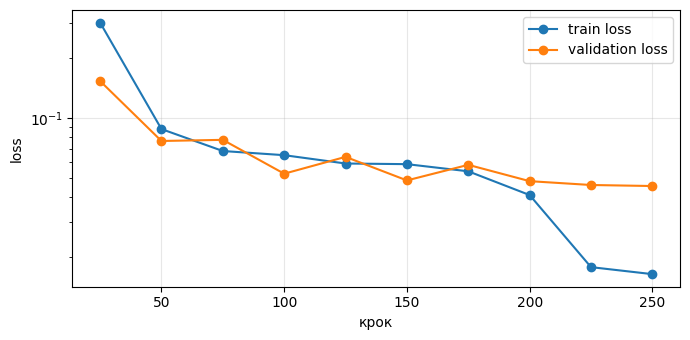

Найменший validation loss 0.0456 на кроці 250; на кроці 250: 0.0456; останній train loss 0.0164
Ознаки перенавчання (validation loss помітно зріс після мінімуму): ні
Розмір адаптера: 69.8 MB


In [ ]:
log = trainer.state.log_history
tr = {l["step"]: l["loss"] for l in log if "loss" in l}
ev = {l["step"]: l["eval_loss"] for l in log if "eval_loss" in l}
steps = sorted(set(tr) | set(ev))
loss_df = pd.DataFrame({"крок": steps, "train loss": [tr.get(s) for s in steps], "validation loss": [ev.get(s) for s in steps]})
display(loss_df.round(4))

plt.figure(figsize=(7, 3.5))
plt.plot(list(tr), list(tr.values()), marker="o", label="train loss")
plt.plot(list(ev), list(ev.values()), marker="o", label="validation loss")
plt.xlabel("крок")
plt.ylabel("loss")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_step = min(ev, key=ev.get)
last_step = max(ev)
overfit = ev[last_step] > 1.15 * ev[best_step] and best_step != last_step
print(f"Найменший validation loss {ev[best_step]:.4f} на кроці {best_step}; на кроці {last_step}: {ev[last_step]:.4f}; "
      f"останній train loss {tr[max(tr)]:.4f}")
print("Ознаки перенавчання (validation loss помітно зріс після мінімуму):", "так" if overfit else "ні")

trainer.model.save_pretrained("uareviews_adapter")
adapter_mb = sum(os.path.getsize(os.path.join("uareviews_adapter", f)) for f in os.listdir("uareviews_adapter") if f.endswith(".safetensors")) / 1e6
print(f"Розмір адаптера: {adapter_mb:.1f} MB")

## 1.5. Порівняння до і після

Порівняння робиться на **тому самому** тестовому наборі й тих самих прикладах. Базова модель - Qwen3-1.7B з найкращим промптом (обраним за val), донавчена - Qwen3-1.7B + LoRA з коротким промптом. Нижче:
1. метрики донавченої моделі поруч з базовими;
2. ті самі 10 тестових прикладів до і після, кількість виправлених і зіпсованих відповідей на всьому тесті;
3. підсумкова таблиця і метрики за класами до і після, а також розрахунок вартості промпту;
4. аналіз помилок: звіт за класами, матриця плутанини, найчастіші пари, приклади;
5. залежність помилок від довжини, джерела й рейтингу;
6. перевірка загальних запитів поза задачею: чи не погіршились відповіді моделі.

In [ ]:
tuned = trainer.model
tuned.eval()
after = run_eval(tuned, test_texts, test_gold, SHORT_PROMPT)
chal_after = run_eval(tuned, chal_texts, chal_gold, SHORT_PROMPT)

print("Після донавчання (test, короткий промпт):", {k: round(float(v), 1) for k, v in after["metrics"].items() if not k.startswith("F1 ")}, f"; {after['time']:.0f} с")
for name, d in base.items():
    print(f"До донавчання (test, {name}):", {k: round(float(v), 1) for k, v in d["metrics"].items() if not k.startswith("F1 ")}, f"; {d['time']:.0f} с")
print(f"challenge: до {chal_before['metrics']['Macro-F1, %']:.1f}, після {chal_after['metrics']['Macro-F1, %']:.1f} (macro-F1)")

Після донавчання (test, короткий промпт): {'Чистий JSON, %': 100.0, 'Валідна відповідь, %': 100.0, 'Accuracy, %': 90.5, 'Macro-F1, %': 78.8} ; 87 с
До донавчання (test, простий): {'Чистий JSON, %': 100.0, 'Валідна відповідь, %': 100.0, 'Accuracy, %': 85.5, 'Macro-F1, %': 69.1} ; 53 с
До донавчання (test, детальний): {'Чистий JSON, %': 100.0, 'Валідна відповідь, %': 100.0, 'Accuracy, %': 88.3, 'Macro-F1, %': 71.0} ; 121 с
challenge: до 65.8, після 77.6 (macro-F1)


In [ ]:
b = base[best_name]["preds"]
a = after["preds"]
for i in range(10):
    print(f"істина: {test_gold[i]} | до: {b[i]} {'✓' if b[i] == test_gold[i] else '✗'} | після: {a[i]} {'✓' if a[i] == test_gold[i] else '✗'}")
    print("    ", repr(test_texts[i][:110]))

fixed = sum(1 for x, y, g in zip(b, a, test_gold) if x != g and y == g)
broken = sum(1 for x, y, g in zip(b, a, test_gold) if x == g and y != g)
both_wrong = sum(1 for x, y, g in zip(b, a, test_gold) if x != g and y != g)
right_before = sum(x == g for x, g in zip(b, test_gold))
right_after = sum(y == g for y, g in zip(a, test_gold))
print(f"\nНа всьому тесті: виправлено {fixed}, зіпсовано {broken}, помилка і до, і після {both_wrong}; "
      f"правильних до {right_before}, після {right_after} з {len(test_gold)}")

істина: gratitude | до: gratitude ✓ | після: gratitude ✓
     'Вчимося в академії перший рік, дитині поки що подобається. Заняття цікаві.'
істина: complaint | до: complaint ✓ | після: complaint ✓
     'Повний провал та саботаж! Перед виборами треба було змінити місце голосування. Працюють вкрай повільно, збираю'
істина: gratitude | до: gratitude ✓ | після: gratitude ✓
     "Чудовий салон! Чудова атмосфера! Чудові майстри ! Обов'язково повернусь за тату і пірсингом. Однозначно 5 зіро"
істина: gratitude | до: gratitude ✓ | після: gratitude ✓
     'Класний коледж, отримую стипендію.\nНавчаюся на 3 курсі.'
істина: gratitude | до: gratitude ✓ | після: gratitude ✓
     'Був на консультації у юриста Максима Юрійовича на всі питання отримав відповідь, роботою задоволений'
істина: complaint | до: complaint ✓ | після: question ✗
     'Світла немає - сервіс не працює 😵\u200d💫 Що таке генератор? ніхто не знає 🥲…'
істина: gratitude | до: gratitude ✓ | після: gratitude ✓
     'Після короткої (30 хв)

In [ ]:
rows = []
for name, d in base.items():
    rows.append({"модель": f"Qwen3-1.7B, {name} промпт", **{k: round(float(v), 1) for k, v in d["metrics"].items() if not k.startswith("F1 ")}, "час, с": round(d["time"])})
rows.append({"модель": "Qwen3-1.7B + LoRA, простий промпт", **{k: round(float(v), 1) for k, v in after["metrics"].items() if not k.startswith("F1 ")}, "час, с": round(after["time"])})
comparison = pd.DataFrame(rows)
display(comparison)

pb, rb, fb, sup = precision_recall_fscore_support(test_gold, [p or "invalid" for p in b], labels=CLASSES, zero_division=0)
a_labels = [p or "invalid" for p in a]
pa, ra, fa, _ = precision_recall_fscore_support(test_gold, a_labels, labels=CLASSES, zero_division=0)
per_class = pd.DataFrame({
    "клас": CLASSES, "у тесті": sup,
    "precision до": pb.round(3), "recall до": rb.round(3), "F1 до": fb.round(3),
    "precision після": pa.round(3), "recall після": ra.round(3), "F1 після": fa.round(3),
    "різниця F1": (fa - fb).round(3),
}).sort_values("різниця F1")
display(per_class)

avg_review = float(np.mean([len(tokenizer(t)["input_ids"]) for t in test_texts]))
cost_rows = []
for name, p in PROMPTS.items():
    per_request = len(tokenizer(build_prompts([""], p)[0])["input_ids"]) + avg_review
    cost_rows.append({"промпт": name, "вхідних токенів на запит": round(per_request), "млн токенів на 10 000 запитів на день": round(per_request * 10_000 / 1e6, 2)})
cost_df = pd.DataFrame(cost_rows)
display(cost_df)
print(f"Середній відгук: {avg_review:.0f} токенів. Донавчена модель працює з простим промптом, а найкращий промпт до донавчання - '{best_name}'.")

,модель,"Чистий JSON, %","Валідна відповідь, %","Accuracy, %","Macro-F1, %","час, с"
0,"Qwen3-1.7B, простий промпт",100.0,100.0,85.5,69.1,53
1,"Qwen3-1.7B, детальний промпт",100.0,100.0,88.3,71.0,121
2,"Qwen3-1.7B + LoRA, простий промпт",100.0,100.0,90.5,78.8,87


,клас,у тесті,precision до,recall до,F1 до,precision після,recall після,F1 після,різниця F1
0,gratitude,624,0.952,0.962,0.957,0.970,0.941,0.955,-0.002
1,complaint,252,0.949,0.813,0.876,0.964,0.841,0.898,0.022
2,question,54,0.925,0.685,0.787,0.850,0.944,0.895,0.108
4,neutral,39,0.298,0.641,0.407,0.455,0.641,0.532,0.125
3,suggestion,31,0.533,0.516,0.525,0.500,0.968,0.659,0.135


,промпт,вхідних токенів на запит,млн токенів на 10 000 запитів на день
0,простий,130,1.30
1,детальний,423,4.23
2,few-shot,783,7.83


Середній відгук: 76 токенів. Донавчена модель працює з простим промптом, а найкращий промпт до донавчання - 'детальний'.


In [ ]:
print(classification_report(test_gold, a_labels, labels=CLASSES, zero_division=0, digits=3))

confusion = pd.crosstab(pd.Series(test_gold, name="істина"), pd.Series(a_labels, name="відповідь"))
display(confusion)

err = [(g, p, o, t) for g, p, o, t in zip(test_gold, a_labels, after["outs"], test_texts) if g != p]
pairs = pd.Series([(g, p) for g, p, _, _ in err]).value_counts()
print(f"Помилок: {len(err)} з {len(test_gold)}")
print("Найчастіші пари (істина -> відповідь):")
for (g, p), n in pairs.head(6).items():
    print(f"  {g} -> {p}: {n}")

for (g, p), n in list(pairs.head(3).items()):
    print(f"\n=== {g} -> {p} ({n}) ===")
    shown = 0
    for gg, pp, o, t in err:
        if (gg, pp) == (g, p):
            print("-", repr(t[:220]))
            shown += 1
            if shown == 4:
                break

              precision    recall  f1-score   support

   gratitude      0.970     0.941     0.955       624
   complaint      0.964     0.841     0.898       252
    question      0.850     0.944     0.895        54
  suggestion      0.500     0.968     0.659        31
     neutral      0.455     0.641     0.532        39

    accuracy                          0.905      1000
   macro avg      0.748     0.867     0.788      1000
weighted avg      0.927     0.905     0.912      1000



відповідь,complaint,gratitude,neutral,question,suggestion
істина,,,,,
complaint,212,10,14,9,7
gratitude,5,587,15,0,17
neutral,2,6,25,0,6
question,1,1,1,51,0
suggestion,0,1,0,0,30


Помилок: 95 з 1000
Найчастіші пари (істина -> відповідь):
  gratitude -> suggestion: 17
  gratitude -> neutral: 15
  complaint -> neutral: 14
  complaint -> gratitude: 10
  complaint -> question: 9
  complaint -> suggestion: 7

=== gratitude -> suggestion (17) ===
- 'Рекомендую Романа Володимировича , надав якісну консультацію'
- 'Піднятися наверх трохи складно, але краєвид вартий зусиль!'
- 'Якби я жив у Львові, то кожного дня підіймався би на Ратушу, це була б гарна ранкова зарядка) Насправді, коли вперше підіймаєшся туди, то сходи здаються безкінечними, але після того, як подолаєш всі сходинки, то на тебе '
- 'Словами не описати мого захвату від цього місця. Обов’язково необхідно тут побувати.\nЕкстер’єр будівлі - не менш вражаючий ніж інтер’єр, а територією Університету…'

=== gratitude -> neutral (15) ===
- "Електронна черга, безкоштовна консультація та користування комп'ютером, санвузлом; сучасний ремонт, їдальня - як кажуть все для людей - головне щоб податки вчасно декларували 

In [ ]:
ana = test_df.copy()
ana["err"] = [g != p for g, p in zip(test_gold, a_labels)]
ana["довжина"] = pd.cut(ana["text"].str.len(), [0, 80, 150, 300, 10**6], labels=["до 80", "80-150", "150-300", "300+"], right=False)
ana["рейтинг"] = ana["rating"].fillna(0).astype(int).map(lambda r: "немає" if r == 0 else str(r))
ana["джерело"] = ana["source"]

breakdowns = {}
for col in ["довжина", "джерело", "рейтинг"]:
    t = ana.groupby(col, observed=True)["err"].agg(["size", "sum", "mean"])
    t.columns = ["прикладів", "помилок", "частка помилок"]
    t["частка помилок"] = (100 * t["частка помилок"]).round(1)
    breakdowns[col] = t
    print(f"--- за колонкою '{col}' ---")
    display(t)

--- за колонкою 'довжина' ---


,прикладів,помилок,частка помилок
довжина,,,
до 80,246,28,11.4
80-150,322,27,8.4
150-300,398,38,9.5
300+,34,2,5.9


--- за колонкою 'джерело' ---


,прикладів,помилок,частка помилок
джерело,,,
cosmus,9,2,22.2
original,991,93,9.4


--- за колонкою 'рейтинг' ---


,прикладів,помилок,частка помилок
рейтинг,,,
1,172,20,11.6
2,29,4,13.8
3,13,5,38.5
4,36,11,30.6
5,636,28,4.4
немає,114,27,23.7


In [ ]:
GENERAL = [
    "Explain in two sentences what a neural network is.",
    "Translate 'good morning, how are you?' into French and Spanish.",
    "Write a Python function that reverses a string.",
    "What is the capital of Ukraine? Give one interesting fact about it.",
    "Поясни простими словами, що таке фотосинтез.",
    "Напиши коротке ввічливе привітання колезі з днем народження.",
]

def chat(model, question, max_new_tokens=120):
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    return generate_batch(model, [prompt], max_new_tokens=max_new_tokens)[0]

tuned.eval()
general_rows = []
for q in GENERAL:
    with tuned.disable_adapter():
        base_answer = chat(tuned, q)
    tuned_answer = chat(tuned, q)
    general_rows.append((q, base_answer, tuned_answer))
    print("Запит:", q)
    print("  до:    ", base_answer.replace("\n", " ")[:260])
    print("  після: ", tuned_answer.replace("\n", " ")[:260])
    print()

leaks = sum(x.lstrip().startswith("{") and '"category"' in x for _, _, x in general_rows)
base_leaks = sum(x.lstrip().startswith("{") and '"category"' in x for _, x, _ in general_rows)
print(f"Відповідей у форматі класифікатора на загальні питання: донавчена {leaks} з {len(GENERAL)}, базова {base_leaks} з {len(GENERAL)}")

Запит: Explain in two sentences what a neural network is.
  до:     A neural network is a computational model inspired by the human brain, consisting of layers of interconnected nodes that process and transmit information. It learns patterns from data to make predictions or decisions.
  після:  A neural network is a computational model inspired by the human brain, consisting of interconnected nodes that process information through layers. It learns patterns and relationships in data to make predictions or decisions.

Запит: Translate 'good morning, how are you?' into French and Spanish.
  до:     **French:** Bonjour, comment ça va ?  **Spanish:** Buenos días, ¿cómo estás?
  після:  **French:** Bonjour, comment ça va ?   **Spanish:** Buenos días, ¿cómo estás?

Запит: Write a Python function that reverses a string.
  до:     Sure! Here's a simple Python function that reverses a string:  ```python def reverse_string(s):     return s[::-1] ```  ### Explanation: - `s[::-1]` is a slicing ope

## 1.6. Мій звіт

### Задача і чому потрібне донавчання

**Задача.** Маршрутизація відгуків громадян про державні й муніципальні послуги. Вхід: текст відгуку українською (до 700 символів). Вихід: JSON `{"category": "..."}` з однією з п'яти міток: `gratitude`, `complaint`, `question`, `suggestion`, `neutral`. Користувач: служба підтримки й аналітики, яка за міткою автоматично спрямовує відгук потрібній команді.

**Чому не лише промпт.**
1. Межі категорій задає конвенція розмітників датасету, а не їхній опис. Наприклад, схвальний відгук із зауваженням про години прийому розмічено як `complaint`. Такі правила модель може лише навчитися на прикладах.
2. Класи сильно незбалансовані: `gratitude` становить 62.4% тесту, а `question`, `suggestion` і `neutral` разом лише 12.4%. Саме рідкісні класи найважливіші для маршрутизації, і саме їх промпт розрізняє гірше за все.
3. Промпт коштує токенів на кожному запиті. Простий промпт має 37 токенів, детальний 330. З урахуванням відгуку й службових токенів чату це 130 і 423 вхідні токени на запит, тобто 1.3 і 4.23 млн токенів на 10 000 запитів на день. Донавчена модель працює з коротким промптом.
4. Відгуки містять персональні дані (прізвища працівників, контакти), тому мала модель на власному залізі краща за зовнішній API.

**Чому не RAG.** RAG додає знання з документів, а тут нових знань не потрібно: категорія визначається самим текстом і конвенцією розмітки. Пошук схожих відгуків додав би індекс і затримку, але не гарантував би ні формат відповіді, ні узгодженість меж між класами.

### Модель і дані

**Модель.** `Qwen/Qwen3-1.7B` (версія після post-training з чат-шаблоном, режим thinking вимкнено), 1.74 млрд параметрів разом з адаптерами. Instruct-подібну модель обрано тому, що вона вже вміє тримати формат JSON за системним промптом. Розмір 1.7B обрано за ресурсами T4. Альтернативи (0.6B, 4B) експериментально не порівнювались.

**Дані.** UAReviews (`KSE-RESEARCH-Group/UAReviews`), ліцензія CC BY 4.0 (за карткою датасету). Після дедуплікації лишилось 11 564 відгуки. Колонка `final_category` дає мітку.

**Поділ.**

| Набір | Розмір | Примітка |
|---|---|---|
| train | 1595 | не більше 400 на клас, рідкісні класи беруться повністю |
| validation | 300 | збалансований, по 60 на клас, із `train` |
| test | 1000 | офіційний `split == "test"`, природний розподіл (gratitude 62.4%) |
| challenge | 400 | додатковий набір, оцінюється окремо |

Перетину між наборами немає (перевірено `assert` і окремим підрахунком), тексти обрізано до 700 символів.

### Метрика й результат до донавчання

**Метрики.** Головна метрика: macro-F1, бо accuracy оманлива при дисбалансі. Відповідь «завжди gratitude» дає accuracy 62.4%, але macro-F1 лише 15.4%. Додатково: accuracy, F1, precision і recall за класами та частка валідних відповідей (невалідна відповідь вважається помилкою).

**Вибір промпту на validation (300 прикладів).**

| | простий | детальний | few-shot |
|---|---|---|---|
| Accuracy, % | 72.3 | 73.3 | 73.0 |
| Macro-F1, % | 71.9 | 72.6 | 71.7 |
| Валідна відповідь, % | 100.0 | 100.0 | 100.0 |

За macro-F1 найкращий детальний промпт, але відрив від решти менший за 1 п.п. і лежить у межах шуму для вибірки з 300 прикладів. Складніший промпт майже нічого не дав.

**Тест до донавчання (1000 відгуків).**

| Модель | Accuracy, % | Macro-F1, % | Валідних, % |
|---|---|---|---|
| Завжди `gratitude` | 62.4 | 15.4 | не застосовується |
| Qwen3-1.7B, простий промпт | 85.5 | 69.1 | 100.0 |
| Qwen3-1.7B, детальний промпт | 88.3 | 71.0 | 100.0 |

F1 за класами (детальний промпт): gratitude 95.7, complaint 87.6, question 78.7, suggestion 52.5, neutral 40.7. На challenge macro-F1 дорівнює 65.8%.

З 10 прикладів відповідей, виведених у 1.3, дев'ять правильні. Помилка одна: відгук «Я вже вчуся тут пар місяців і мені дуже подобається. Тільки зміна за 2 пари одна на 10 хвилин.» з міткою `neutral` модель віднесла до `gratitude`.

### Метод донавчання й гіперпараметри

SFT з LoRA: ваги базової моделі (fp16) заморожені, навчаються адаптери в усіх лінійних шарах. Повне донавчання на T4 нереалістичне, а QLoRA не потрібна, бо модель у fp16 вміщується в памʼять.

| Параметр | Значення |
|---|---|
| LoRA r / lora_alpha / dropout | 16 / 32 / 0.05 |
| target_modules | all-linear |
| learning rate | 2e-4, cosine, warmup 10 кроків |
| Батч | 4 × 2 (накопичення градієнта) = 8 |
| Кроки | 250 (≈ 1.25 епохи) |
| max_length | 512 |
| Точність | fp16 + gradient checkpointing |
| Loss | лише на відповіді асистента (`assistant_only_loss=True`) |
| Промпт у тренуванні | короткий, межі категорій модель вчить у вагах |

Значення взято зі стандартних рекомендацій для LoRA та з демо 3, окремий підбір гіперпараметрів не проводився. Навчалось 17 432 576 із 1 738 007 552 параметрів (1.00%).

**Ресурси.** Тривалість тренування 9.31 хв, пікова памʼять GPU 4.38 GB, розмір адаптера 69.8 MB.

**Перенавчання.** Validation loss знижувався впродовж усього тренування від 0.1540 на кроці 25 до мінімуму 0.0456 на кроці 250 (останній train loss 0.0164). Після мінімуму зростання не було, тож перенавчання не виявлено й гіперпараметри після першого запуску не змінювались. Розрив між train і validation loss наприкінці (0.0164 проти 0.0456) відносно великий, і при довшому тренуванні варто стежити за ним.

### Результат після донавчання

**Порівняння на одному тесті (1000 відгуків).**

| Модель | Чистий JSON, % | Валідна відповідь, % | Accuracy, % | Macro-F1, % | Час, с |
|---|---|---|---|---|---|
| Qwen3-1.7B, простий промпт | 100.0 | 100.0 | 85.5 | 69.1 | 53 |
| Qwen3-1.7B, детальний промпт | 100.0 | 100.0 | 88.3 | 71.0 | 121 |
| Qwen3-1.7B + LoRA, простий промпт | 100.0 | 100.0 | 90.5 | 78.8 | 87 |

Порівняно з найкращим промптом донавчання виправило 62 відповіді й зіпсувало 40, ще 55 лишились помилковими і до, і після. Правильних відповідей стало 905 проти 883. На challenge macro-F1 зріс із 65.8% до 77.6%.

**Зміна F1 за класами.**

| Клас | У тесті | F1 до | F1 після | Різниця |
|---|---|---|---|---|
| gratitude | 624 | 0.957 | 0.955 | -0.002 |
| complaint | 252 | 0.876 | 0.898 | +0.022 |
| question | 54 | 0.787 | 0.895 | +0.108 |
| neutral | 39 | 0.407 | 0.532 | +0.125 |
| suggestion | 31 | 0.525 | 0.659 | +0.135 |

**Загальні запити поза задачею.** Модель з вимкненим і ввімкненим адаптером перевірено на 6 запитах (англійською й українською: пояснення, переклад, код, факт, привітання). Відповідей у форматі класифікатора немає ні в базової, ні в донавченої моделі (0 із 6). Англомовні відповіді, переклад і код майже збігаються до і після. Відповіді українською слабкі в обох варіантах, зі спотвореними словами. У донавченої моделі в привітанні колезі зʼявились повтори фраз. Помітного погіршення за цією малою перевіркою немає, але шість запитів не дають підстав для сильних висновків.

**Вартість промпту.**

| Промпт | Вхідних токенів на запит | Млн токенів на 10 000 запитів на день |
|---|---|---|
| простий | 130 | 1.3 |
| детальний | 423 | 4.23 |
| few-shot | 783 | 7.83 |

### Аналіз помилок

Донавчена модель помилилась у 95 випадках із 1000.

**Матриця плутанини** (рядки: істина, стовпці: відповідь).

| | complaint | gratitude | neutral | question | suggestion |
|---|---|---|---|---|---|
| complaint | 212 | 10 | 14 | 9 | 7 |
| gratitude | 5 | 587 | 15 | 0 | 17 |
| neutral | 2 | 6 | 25 | 0 | 6 |
| question | 1 | 1 | 1 | 51 | 0 |
| suggestion | 0 | 1 | 0 | 0 | 30 |

**Precision і recall після донавчання.**

| Клас | Precision | Recall |
|---|---|---|
| gratitude | 0.970 | 0.941 |
| complaint | 0.964 | 0.841 |
| question | 0.850 | 0.944 |
| suggestion | 0.500 | 0.968 |
| neutral | 0.455 | 0.641 |

**Головна закономірність: надмірне передбачення рідкісних класів.** У `suggestion` recall 0.968, але precision лише 0.500: із 60 відповідей `suggestion` правильних 30, а 17 із помилкових припадає на `gratitude`. У `neutral` precision 0.455 (25 правильних із 55). Із 37 помилок класу `gratitude` 32 припадають на `suggestion` (17) і `neutral` (15). До донавчання recall `suggestion` був 0.516, тобто модель зсунулась убік рідкісних класів. Ймовірна причина: у тренуванні `gratitude` становив 400 із 1595 прикладів (25%), а в тесті 62%, тож модель навчилась у розподілі, де рідкісні класи трапляються набагато частіше. Це припущення не перевірялось окремим експериментом, наприклад, навчанням на природному розподілі чи калібруванням порогів.

**Типи помилок із прикладами з тесту.**
- **`gratitude` → `suggestion` (17).** Позитивні відгуки з порадою або обовʼязковою умовою: «Рекомендую Романа Володимировича, надав якісну консультацію»; «Піднятися наверх трохи складно, але краєвид вартий зусиль!». Модель, імовірно, реагує на слова на кшталт «рекомендую» чи «потрібно» і сприймає їх як пропозицію.
- **`gratitude` → `neutral` (15).** Позитив без явної подяки: «Хороший коледж з деякими викладачами досі утримую контакт. Закінчив 2008»; «Ті, хто не бачили ратушу, не відвідували Львів. Місцева класика!».
- **`complaint` → `neutral` (14).** Скарга без емоційних маркерів або висловлена фактом: «Будівля досі не декомунізована, на стінах досі серпи та молоти»; «Черги як при радянскому сoюзi». Тут ще заважають орфографічні помилки та змішання латиниці з кирилицею.
- **`complaint` → `question` (9).** Риторичні питання в скарзі: «Світла немає - сервіс не працює. Що таке генератор? ніхто не знає». До донавчання модель класифікувала цей відгук правильно, тож це приклад із 40 зіпсованих відповідей.
- **Неоднозначна розмітка.** Відгук «Мені дуже подобається. Тільки зміна за 2 пари одна на 10 хвилин» має мітку `neutral`, а обидві моделі вважають його `gratitude`. Схоже, що це шум розмітки, а не помилка моделі.

**Залежність помилок від характеристик відгуку.**

| Ознака | Група | Прикладів | Частка помилок, % |
|---|---|---|---|
| Рейтинг | 5 | 636 | 4.4 |
| | 3 | 13 | 38.5 |
| | 4 | 36 | 30.6 |
| | 1 | 172 | 11.6 |
| | немає | 114 | 23.7 |
| Довжина, символів | до 80 | 246 | 11.4 |
| | 80-150 | 322 | 8.4 |
| | 150-300 | 398 | 9.5 |
| | 300+ | 34 | 5.9 |
| Джерело | original | 991 | 9.4 |
| | cosmus | 9 | 22.2 |

Найпомітніша залежність від рейтингу: помилок набагато більше у відгуках із рейтингом 3-4 (змішана оцінка, змішаний тон) і без рейтингу, ніж при рейтингу 5 (4.4%). Довжина впливає слабко й нерівномірно, групу 300+ складають лише 34 приклади. Висновок щодо джерела `cosmus` статистично ненадійний: 22.2% це 2 помилки на 9 прикладів.

### Висновок

Донавчання (LoRA, 250 кроків, 9.31 хв, 4.38 GB) підняло macro-F1 на тесті з 71.0% (найкращий промпт) до 78.8%, accuracy з 88.3% до 90.5%, а на challenge macro-F1 з 65.8% до 77.6%. Найбільше зросла F1 рідкісних класів: `suggestion` (+0.135), `neutral` (+0.125) та `question` (+0.108), тоді як `gratitude` не змінився. Валідний JSON у 100% відповідей, а промпт скоротився з 330 до 37 токенів. Усі чотири критерії успіху з 1.1 виконано: macro-F1 вищий за найкращий промпт, формат 100% валідний, промпт короткий, а на загальних запитах формат класифікатора не зʼявляється.

Приріст має ціну: модель зсунулась до рідкісних класів, тож precision `suggestion` (0.50) і `neutral` (0.455) низька, а багато позитивних відгуків потрапляє в `suggestion` чи `neutral`. Для маршрутизації важливіше інше: 24 скарги з 252 (10 у `gratitude` і 14 у `neutral`) потрапили б у статистику чи архів, а не в чергу швидкого реагування (recall `complaint` 0.841). Для точнішого розподілу варто спробувати тренування на природному розподілі класів або підбір порога.

**Обмеження.** Один датасет, один запуск із фіксованим seed. У тесті лише 31 приклад `suggestion` і 39 `neutral`, тож різниці в кілька пунктів для цих класів лежать у межах шуму. Розмітка містить суб'єктивні випадки. Гіперпараметри не підбирались, моделі 0.6B і 4B не порівнювались, перевірка на загальних запитах обмежена шістьма прикладами.